In [1]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('Auto-mpg.csv')
df.head()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model year,origin,car name
0,18.0,8,307.0,130,3504,12.0,70,1,chevrolet chevelle malibu
1,15.0,8,350.0,165,3693,11.5,70,1,buick skylark 320
2,18.0,8,318.0,150,3436,11.0,70,1,plymouth satellite
3,16.0,8,304.0,150,3433,12.0,70,1,amc rebel sst
4,17.0,8,302.0,140,3449,10.5,70,1,ford torino


# Linear regression 

In [3]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer

# Preparation

 # Select Features Target

In [4]:
# Features and target
X = df.drop(columns='mpg')
y = df['mpg']

# Define Numerical and Categorical features

In [5]:
df['horsepower'] = pd.to_numeric(
    df['horsepower'],
    errors='coerce'
) 

In [6]:
# Numerical features
numeric_features = [
    'cylinders',
    'displacement',
    'horsepower',
    'weight',
    'acceleration',
    'model year'
]


In [7]:
# Categorical features
categorical_features = [
    'origin',
    'car name'
]

# Create the 2 Pipelines

In [8]:
# Numerical pipeline
numeric_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

In [9]:
# Categorical pipeline
categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

# Apply the transformations to numerical and categorical columns

In [10]:
# Preprocessor
X_numeric = numeric_pipeline.fit_transform(df[numeric_features])

df_reg = pd.DataFrame(X_numeric,columns = numeric_features,index = df.index)
df_reg


,cylinders,displacement,horsepower,weight,acceleration,model year
0,1.498191,1.090604,0.673118,0.630870,-1.295498,-1.627426
1,1.498191,1.503514,1.589958,0.854333,-1.477038,-1.627426
2,1.498191,1.196232,1.197027,0.550470,-1.658577,-1.627426
3,1.498191,1.061796,1.197027,0.546923,-1.295498,-1.627426
4,1.498191,1.042591,0.935072,0.565841,-1.840117,-1.627426
...,...,...,...,...,...,...
393,-0.856321,-0.513026,-0.479482,-0.213324,0.011586,1.621983
394,-0.856321,-0.925936,-1.370127,-0.993671,3.279296,1.621983
395,-0.856321,-0.561039,-0.531873,-0.798585,-1.440730,1.621983
396,-0.856321,-0.705077,-0.662850,-0.408411,1.100822,1.621983


In [11]:
X_categorical = categorical_pipeline.fit_transform(
    df[categorical_features]
)

# With Categorical we need to recover also the names of the columns

In [12]:
X_categorical_columns = (
    categorical_pipeline
    .named_steps['onehot']
    .get_feature_names_out(categorical_features)
)

In [13]:
X_categorical_df = pd.DataFrame(
    X_categorical.toarray(),
    columns=X_categorical_columns,
    index=df.index
)

# Create the df for the Regression


In [14]:
df_ml = pd.concat(
    [
        df_reg,
        X_categorical_df,
        df[['mpg']]
    ],
    axis=1
)

# OLS method 

In [15]:
from sklearn.model_selection import train_test_split

X = df_ml.drop(columns='mpg')
y = df_ml['mpg']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [16]:
import statsmodels as sm
import statsmodels.api as sm

In [17]:
X_train = sm.add_constant(X_train)
model = sm.OLS(y_train,X_train)
results = model.fit()

In [18]:
results.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                    mpg   R-squared:                       0.982
Model:                            OLS   Adj. R-squared:                  0.912
Method:                 Least Squares   F-statistic:                     14.04
Date:                Mon, 31 Aug 2026   Prob (F-statistic):           5.71e-25
Time:                        10:50:41   Log-Likelihood:                -473.79
No. Observations:                 318   AIC:                             1452.
Df Residuals:                      66   BIC:                             2400.
Df Model:                         251                                         
Covariance Type:            nonrobust                                         
=================================================================================================================
                                                    coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------------------------------
const                                            17.9086      0.364     49.236      0.000      17.182      18.635
cylinders                                        -1.4329      1.207     -1.187      0.239      -3.843       0.977
displacement                                     -1.4428      1.756     -0.822      0.414      -4.948       2.062
horsepower                                       -0.5750      1.177     -0.489      0.627      -2.925       1.774
weight                                           -3.0423      1.175     -2.589      0.012      -5.389      -0.696
acceleration                                     -1.1793      0.525     -2.246      0.028      -2.227      -0.131
model year                                        2.1671      0.480      4.517      0.000       1.209       3.125
origin_1                                          5.1344      0.935      5.492      0.000       3.268       7.001
origin_2                                          6.4230      0.612     10.499      0.000       5.202       7.644
origin_3                                          6.3513      0.778      8.159      0.000       4.797       7.905
car name_amc ambassador brougham                 -1.6535      2.648     -0.624      0.535      -6.941       3.634
car name_amc ambassador dpl                   -1.587e-14   9.33e-15     -1.701      0.094   -3.45e-14    2.75e-15
car name_amc ambassador sst                       1.4590      2.581      0.565      0.574      -3.693       6.611
car name_amc concord                             -1.7642      1.838     -0.960      0.341      -5.435       1.906
car name_amc concord d/l                      -5.817e-15   3.32e-15     -1.752      0.084   -1.24e-14    8.13e-16
car name_amc concord dl                          -3.1915      2.801     -1.139      0.259      -8.784       2.401
car name_amc concord dl 6                        -1.6321      2.458     -0.664      0.509      -6.540       3.276
car name_amc gremlin                             -1.4598      1.615     -0.904      0.369      -4.684       1.764
car name_amc hornet                              -1.1383      1.393     -0.817      0.417      -3.919       1.642
car name_amc hornet sportabout (sw)           -1.112e-14    7.2e-15     -1.545      0.127   -2.55e-14    3.26e-15
car name_amc matador                             -1.1536      1.217     -0.948      0.347      -3.584       1.277
car name_amc matador (sw)                     -1.277e-14   1.33e-14     -0.957      0.342   -3.94e-14    1.39e-14
car name_amc pacer                               -1.1929      2.457     -0.486      0.629      -6.099       3.713
car name_amc pacer d/l                           -2.5664      2.534     -1.013      0.315      -7.626       2.493
car n

# HOW TO READ THE OLS TABLE

**OLS** - Ordinary Least Square it aims to find the line that better fit to the observed points

The OLS table allow us to assess our model by pay attetion to:

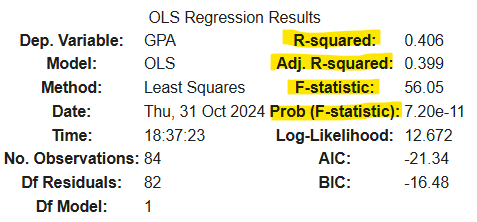


## Top Part

**R2**  this tell us how much our model is able to explain the variability

**Adjusted R2**  this explain how much the explainatory power of the model change by adding more variables

- When lower than  R2  means that the model lost power from the addition of variables

- When higher than  R2  means thta the model improved the power by adding new variables

**F−statistic**  - this is a number that can go from 0 to a very high positive number. It tell us how good the model is in explain the variability of our Y by using X

- F−statistic close to 0 means that our X is not good in explain the variability of Y.
- F−statistic high means that the X well explain the variability of Y

**Prob(F−Statistic)**  - is the p-value related to the F distribution if this is low or generally < alpha then means that our indipendent variables are significative to predict our dependat variable. 

Other way the model is not significant

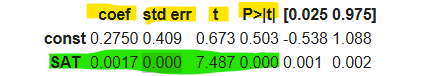

**Const line** refers to our dependant variables

*Coeff* - it tells us that the line cross the y at 0.275 when the X is 0

*Std err* - it tells us what is the error in the calculation of the coefficient
the lower the more the calculation is precise. (lower the better)

*t* - is the t-test for the intercept. The lower it means that our intercept is not significant

*P>|t|* - a p value for the intercept tells us if we can say that the intercept is significantly different than 0. HOWEVER NORMALLY THIS PARAMETER IS NOT IMPORTANT FOR THE MODEL IF P > 0.05

*[0.025, 0.975] (-0.538, 1.088)* is the confidence intervale between 2.5% and 97.5% and tells us that the intercept value can be netween -0.538 and 1.088

**inDependant variable line** is the most important part of the OLS table

*Coeff* - it tells us how Y  change  for each increase of SAT of 1 point

*Std err* - it tells us what is the error in the calculation of the coefficient
the lower the more the calculation is precise. (lower the better)

*t* - tells us if the SAT coefficient is different than 0. The higher means that our dependant variable has a real impact on the variability of the dependant variable.

*P>|t|* - a p value for the dependant variable tells us if we can say that the this variable is significant. a p<0.05 means that the variable is significant

In [19]:
res = results.predict(sm.add_constant(X_test))

In [20]:
from sklearn.metrics import mean_squared_error, mean_absolute_error,mean_absolute_percentage_error

In [21]:
print(f'MAE:{mean_absolute_error(y_test,res)}n\
      MAPE:{mean_absolute_percentage_error(y_test,res)}')

MAE:2.4911408735650022n      MAPE:0.1187308495321949


# Alterntively we can possibly use sklearn

In [39]:
from sklearn.linear_model import LinearRegression

In [40]:
X1 = df_ml.drop(columns='mpg')
y2 = df_ml['mpg']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [41]:
model = LinearRegression()

In [42]:
model.fit(X_train,y_train) # we train our model


LinearRegression()

In [43]:
res = model.predict(X_test)
res

array([27.70687846, 29.16868762, 20.02347236, 16.04337358, 12.65800213,
       27.56161209, 28.77448579,  9.69592904, 15.12121235, 20.38027679,
       13.25860953, 31.43299521, 24.84757788, 14.36248104, 22.04645841,
        8.83381935, 30.39662679, 25.50831787, 14.93421175, 33.81072125,
       25.37289704, 19.04853031, 26.34747808, 29.61361994, 14.35380515,
       30.47950175, 28.02278967, 26.369182  , 21.27996333,  9.71580536,
       29.47718435, 34.55889103, 16.08256033, 27.02240731, 33.08912786,
       12.31026489, 23.81375441, 18.97791016, 12.89280721, 28.45232529,
       26.61560622, 27.36659979, 24.81131406,  8.19097923, 26.50336253,
       33.75159453, 29.29677719, 25.27282656, 24.85188475, 26.69661517,
       23.15139943, 33.17440117, 33.49537569, 10.52348269, 28.40967863,
       10.43972904, 17.30754009, 29.94375746, 24.89685534, 20.49312322,
       15.32245551, 33.99200012, 22.99705961, 22.89539209, 20.33948444,
       25.15992765, 25.90244031, 32.21145713, 26.39841978, 13.23

# Use the result on Original dataframe

In [48]:
X_test_original = df.loc[X_test.index].drop(columns='mpg').copy()

In [49]:
X_test_original['predicted_mpg'] = res

X_test_original.head()

,cylinders,displacement,horsepower,weight,acceleration,model year,origin,car name,predicted_mpg
198,4,91.0,53.0,1795,17.4,76,3,honda civic,27.706878
396,4,120.0,79.0,2625,18.6,82,1,ford ranger,29.168688
33,6,232.0,100.0,2634,13.0,71,1,amc gremlin,20.023472
208,8,318.0,150.0,3940,13.2,76,1,plymouth volare premier v8,16.043374
93,8,318.0,150.0,4237,14.5,73,1,plymouth fury gran sedan,12.658002


In [50]:
MAE = mean_absolute_error(y_test,res)
MAPE = mean_absolute_percentage_error(y_test,res)

print(f'MAE: {MAE},MAPE:{MAPE}')

MAE: 2.4961774716481715,MAPE:0.11897167764696386


## Model Evaluation - Residual Error

We can evaluate the model plotting the differences between y_test and prediction and see if the plot follow any specific pattern.

If there is a visible pattern it sould be considered a  different type of regression

In [51]:
y_residual=y_test-res

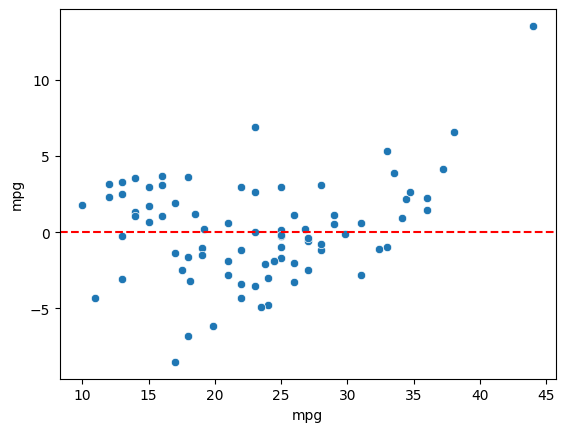

In [52]:
sns.scatterplot(x=y_test,y=y_residual)
plt.axhline(y=0,color='r',linestyle='--');

The plot does not follow any specific pattern which means the linear regression might be appropriate for the problem.

Other way we could consider a different type of regression such as polynomial regression.